In [ ]:
# bài 5.1
import numpy as np

n = 10
P = np.zeros((n, n), dtype=int)
P[0, 0] = 1
for i in range(1, n):
    P[i, 0] = 1
    P[i, 1:] = P[i-1, 1:] + P[i-1, :-1]   # P[i,j] = P[i-1,j] + P[i-1,j-1]

In [ ]:
P[4, :5]

array([1, 4, 6, 4, 1])

In [ ]:
P[9, :10]

array([  1,   9,  36,  84, 126, 126,  84,  36,   9,   1])

In [ ]:
P[9, 4]

np.int64(126)

In [ ]:
np.sum(P[9, :])

np.int64(512)

In [ ]:
# bài 5.6
import numpy as np
A = np.array([
    [2, 1, -1, 0],
    [1, 3, 2, 1],
    [0, -1, 4, 2],
    [3, 2, 0, 1]
], dtype=float)
x = np.array([1, -1, 2, 3])

In [ ]:
# b = A.x
b = A @ x

In [ ]:
b

array([-1.,  5., 15.,  4.])

In [ ]:
# Giải hpt
x = np.linalg.solve(A, b)

In [ ]:
x

array([ 1., -1.,  2.,  3.])

In [ ]:
# Thay h4 bằng tổng h1 và h2
A[3] = A[0] + A[1]

In [ ]:
# Giải lại hệ với h4 mới
try:
    x = np.linalg.solve(A, b)
    print("Nghiem:", x)
except np.linalg.LinAlgError as e:
    print("Loi:", e)

Nghiem: [-0.16666667 -0.66666667  0.          7.16666667]


In [ ]:
# bài 5.7
import numpy as np

x = np.array([0, 1, 2, 3], dtype=float)
y = np.array([1, 0, 5, 22], dtype=float)

A = np.vander(x, increasing=True)


In [ ]:
# Giải hpt
c = np.linalg.solve(A, y)

In [ ]:
c

array([ 1., -2., -0.,  1.])

In [ ]:
# Tinh p(1.5)
x0 = 1.5
p = c[0] + c[1]*x0 + c[2]*x0**2 + c[3]*x0**3


In [ ]:
p

np.float64(1.375)

In [ ]:
# bài 5.8

import numpy as np
import time

# Tạo ma trận
rng = np.random.default_rng(0)
A = rng.random((500, 500))
b = rng.random(500)

# solve
t1 = time.time()
x1 = np.linalg.solve(A, b)
time1 = time.time() - t1

# inv(A) @ b
t2 = time.time()
x2 = np.linalg.inv(A) @ b
time2 = time.time() - t2

# Tính phan du
r1 = np.linalg.norm(A @ x1 - b)
r2 = np.linalg.norm(A @ x2 - b)

# Phan du solve
print("phan du solve: ", r1)
# Thoi gian solve
print("thoi gian solve:",time)

# Phan du inv
print("phan du inv: ", r2)
# thoi gian inv
print("thoi gian inv:",time2)

# Kiem tra
assert r1 < 1e-8
assert r2 < 1e-8
assert np.allclose(x1, x2)



phan du solve:  8.058540555394598e-13
thoi gian solve: <module 'time' (built-in)>
phan du inv:  2.3621299704879234e-12
thoi gian inv: 0.02742171287536621


In [34]:

import pandas as pd

ds = []

while True:
    ho_ten = input("Nhap ho ten: ")

    if ho_ten == "":
        break

    ma_sv = input("Nhap ma sinh vien: ")
    ngay_sinh = input("Nhap ngay sinh: ")

    ds.append([ho_ten, ma_sv, ngay_sinh])

# Tao DataFrame
df = pd.DataFrame(ds, columns=["HoTen", "MaSV", "NgaySinh"])

# Chuyen ngay sinh sang kieu thoi gian
df["NgaySinh"] = pd.to_datetime(
    df["NgaySinh"], format="%d/%m/%Y"
)

# Tinh tuoi tai moc 01/01/2026
moc = pd.Timestamp("2026-01-01")

df["Tuoi"] = ((moc - df["NgaySinh"]).dt.days / 365.25).astype(int)

# Luu ra file Excel
df.to_excel("students.xlsx", index=False)

# Doc lai file de kiem tra
df2 = pd.read_excel("students.xlsx")
df2.head()



Nhap ho ten: nguyen van a
Nhap ma sinh vien: 112
Nhap ngay sinh: 17/11/2000
Nhap ho ten: smith nguyen 
Nhap ma sinh vien: 114
Nhap ngay sinh: 12/11/2010
Nhap ho ten: mdaa pakit
Nhap ma sinh vien: 115
Nhap ngay sinh: 11/10/2009
Nhap ho ten: 


,HoTen,MaSV,NgaySinh,Tuoi
0,nguyen van a,112,2000-11-17,25
1,smith nguyen,114,2010-11-12,15
2,mdaa pakit,115,2009-10-11,16


In [41]:
# bài 6.3
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = (
    pd.read_csv("200heightsweights.csv")
    .rename(columns={
        "Height(Inches)": "Height_in",
        "Weight(Pounds)": "Weight_lb"
    })
    .assign(
        Height_cm=lambda x: x["Height_in"] * 2.54,
        Weight_kg=lambda x: x["Weight_lb"] * 0.453592
    )
    .assign(
        Height_cm=lambda x: x["Height_cm"].fillna(
            x["Height_cm"].mean()
        ),
        Weight_kg=lambda x: x["Weight_kg"].fillna(
            x["Weight_kg"].mean()
        )
    )
    .assign(
        BMI=lambda x: x["Weight_kg"] / (x["Height_cm"] / 100) ** 2
    )
)

df.head()

,Index,Height_in,Weight_lb,Height_cm,Weight_kg,BMI
0,1,65.78,112.99,167.0812,51.251360,18.359051
1,2,71.52,136.49,181.6608,61.910772,18.760473
2,3,69.40,153.03,176.2760,69.413184,22.338581
3,4,68.22,142.34,173.2788,64.564285,21.503120
4,5,67.79,144.30,172.1866,65.453326,22.076642


In [42]:
# Dem so nguoi co BMI < 18.5
dem = (df["BMI"] < 18.5).sum()
print("So nguoi co BMI < 18.5:", dem)

# Chia chieu cao thanh 3 nhom
df["Nhom"] = pd.cut(
    df["Height_cm"],
    bins=[-np.inf, 170, 175, np.inf],
    labels=["Thap", "Trung binh", "Cao"],
    right=False
)

print("\nSo nguoi trong tung nhom:")
print(df["Nhom"].value_counts().sort_index())

# Tinh ti le BMI < 18.5 theo tung nhom
df["Gay"] = df["BMI"] < 18.5

print("\nTi le BMI < 18.5 theo nhom:")
print(df.groupby("Nhom", observed=False)["Gay"].mean())


So nguoi co BMI < 18.5: 50

So nguoi trong tung nhom:
Nhom
Thap          62
Trung binh    81
Cao           57
Name: count, dtype: int64

Ti le BMI < 18.5 theo nhom:
Nhom
Thap          0.258065
Trung binh    0.234568
Cao           0.263158
Name: Gay, dtype: float64


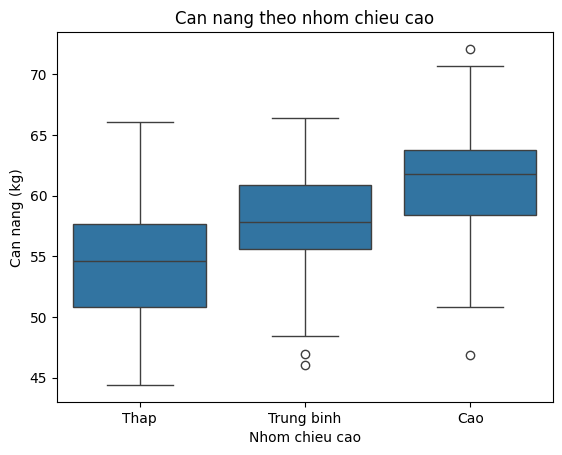

In [44]:
# boxplot can nang theo nhom chieu cao
sns.boxplot(data=df, x="Nhom", y="Weight_kg")

plt.xlabel("Nhom chieu cao")
plt.ylabel("Can nang (kg)")
plt.title("Can nang theo nhom chieu cao")
plt.savefig("box.png")
plt.show()

In [47]:
#bieu do phan tan bang Plotly
try:
    import plotly.express as px

    fig = px.scatter(
        df,
        x="Height_cm",
        y="Weight_kg",
        color="Nhom",
        title="Chieu cao va can nang theo nhom"
    )

    fig.show()

except ImportError:
    print("Chua cai dat Plotly")


In [55]:
# bài 6.4
import pandas as pd
import numpy as np

df = pd.read_csv("core_HRdata.csv")
df["Department"] = df["Department"].str.strip()
print("Số phòng ban:", df["Department"].nunique())


Số phòng ban: 6


In [50]:
# Bảng lương trung bình theo phòng ban và giới tính
bang_luong = df.groupby(
    ["Department", "Sex"]
)["Pay Rate"].mean().unstack()

print("\nBảng lương trung bình:")
print(bang_luong)


Bảng lương trung bình:
Sex                      Female       Male
Department                                
Admin Offices         26.160000  40.500000
Executive Office      80.000000        NaN
IT/IS                 42.536316  46.740455
Production            22.613701  23.827284
Sales                 55.683333  55.375000
Software Engineering  52.330000  43.167500


In [51]:
# Tính thâm niên đến ngày 01/01/2017
df["Date of Hire"] = pd.to_datetime(df["Date of Hire"])
moc_thoi_gian = pd.Timestamp("2017-01-01")
df["Tham_nien"] = (
    (moc_thoi_gian - df["Date of Hire"]).dt.days // 365
)

In [52]:
# Sắp xếp thâm niên giảm dần, tên nhân viên tăng dần
top_5 = df.sort_values(
    ["Tham_nien", "Employee Name"],
    ascending=[False, True]
).head(5)

print("\n5 nhân viên có thâm niên cao nhất:")
print(top_5[["Employee Name", "Date of Hire", "Tham_nien"]])


5 nhân viên có thâm niên cao nhất:
        Employee Name Date of Hire  Tham_nien
282  Riordan, Michael   2006-01-09         10
165       Pitt, Brad    2007-11-05          9
254  Thibaud, Kenneth   2007-06-25          9
68       Alagbe,Trina   2008-01-07          8
0          Brown, Mia   2008-10-27          8


In [54]:
# Thống kê số nhân viên theo Performance Score
thong_ke = df["Performance Score"].value_counts()

print(thong_ke)

Performance Score
Fully Meets                 172
N/A- too early to review     37
90-day meets                 31
Exceeds                      28
Needs Improvement            15
Exceptional                   9
PIP                           9
Name: count, dtype: int64
